# StatEDA-Explorer Demo

This notebook demonstrates the unified Exploratory Data Analysis and Hypothesis Testing engine.

In [1]:
import seaborn as sns
from stateda.pipeline import StatEDAPipeline

# Load a standard Seaborn dataset
df = sns.load_dataset('tips')
display(df.head())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# 1. Initialize the Unified Pipeline
pipeline = StatEDAPipeline(df)

# 2. Check for Multicollinearity (VIF Scores)
print("--- Multicollinearity (VIF) Assessment ---")
vif = pipeline.run_collinearity_check()
display(vif)

--- Multicollinearity (VIF) Assessment ---


,Feature,VIF Score
0,total_bill,2.226294
1,tip,1.879238
2,size,1.590524


In [3]:
# 3. Run Automated Hypothesis Testing
# Is the total bill significantly different between Male and Female customers?
print("--- Automated Hypothesis Test (Total Bill ~ Sex) ---")
test_res = pipeline.run_hypothesis_test(target_col='total_bill', group_col='sex', group1='Male', group2='Female')
for k, v in test_res.items():
    print(f"{k}: {v}")

--- Automated Hypothesis Test (Total Bill ~ Sex) ---
Target: total_bill
Groups: Male vs Female
Distributions Normal: False
Test Applied: Mann-Whitney U Test
Statistic: 8045.5
P-Value: 0.0214
Effect Size (Cohen's d): 0.3044
Significant (alpha=0.05): True


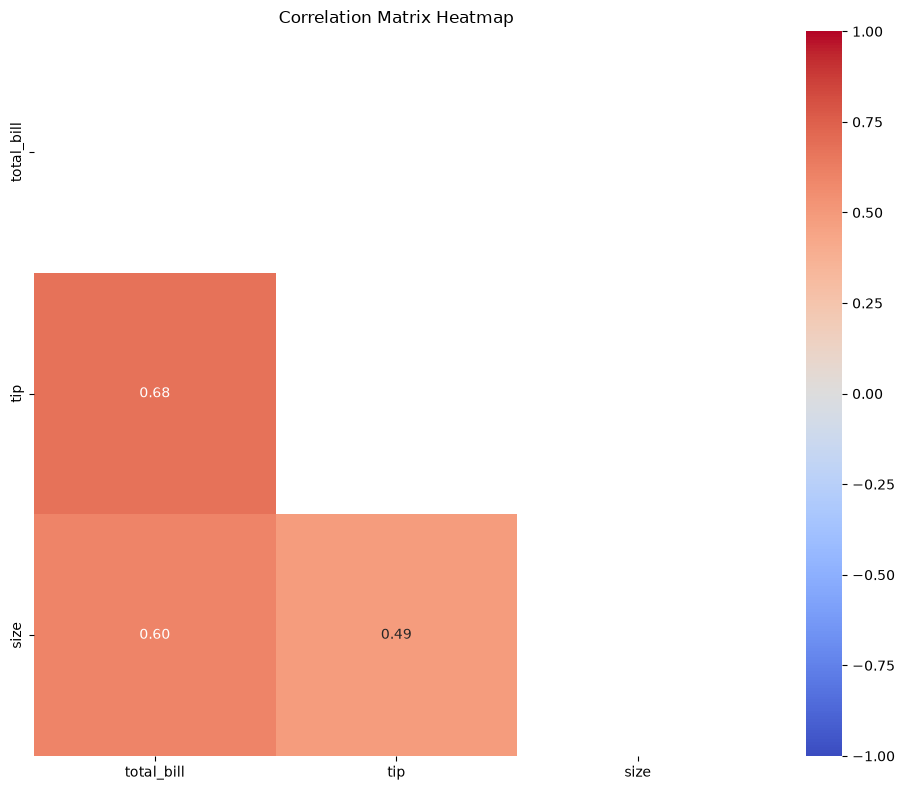

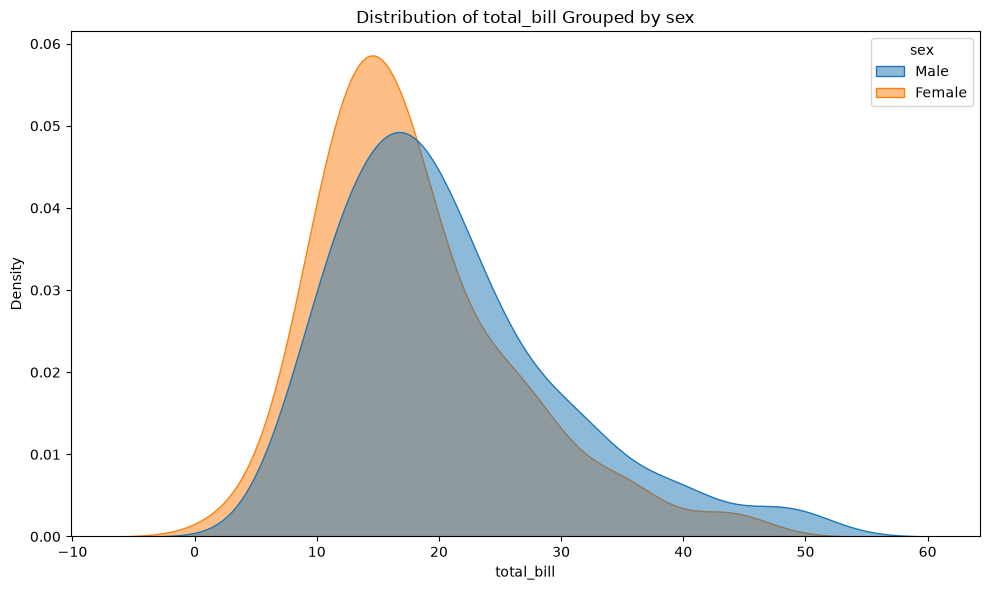

In [5]:
# 4. Visualizations
pipeline.visualize_eda(target_dist_col='total_bill', group_dist_col='sex')